# FFT-Labeled Heston Dataset: NN and GPR

Generate 100,000 European-call prices with the Heston Carr-Madan FFT, then train a feed-forward neural network and a paper-style Gaussian Process Regression surrogate on the same FFT target. Training and validation/test splits are by independent Heston contexts, so all strikes from a context stay together and held-out contexts are unseen.

The NN uses the full training split. Exact GPR has cubic fitting cost, so the default GPR subset is 5,000 rows (configurable, and comparable with the paper's 5k/10k/20k experiments). GPR uses a quadratic trend, ARD squared-exponential kernel, positive observation noise, and standardized features/targets.

In [1]:
from pathlib import Path
import sys
import time
import copy

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from heston_pricing import (SPOT, FEATURE_NAMES, sample_contexts,
                            heston_fft_calls, feature_matrix)

DATA_DIR, MODEL_DIR = ROOT / "data", ROOT / "models"
DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
SEED = 2027
N_CONTEXTS, STRIKES_PER_CONTEXT = 5_000, 20
N_TOTAL = N_CONTEXTS * STRIKES_PER_CONTEXT
FFT_N, FFT_ETA, FFT_ALPHA = 4096, 0.25, 1.25
GPR_N = 5_000
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
plt.style.use("seaborn-v0_8-whitegrid")
print(f"Rows={N_TOTAL:,}; device={DEVICE}; GPR subset={GPR_N:,}")

Rows=100,000; device=mps; GPR subset=5,000


## 1. Generate the FFT-labeled data

The paper fixes spot at one and samples strike as a percentage of the forward price. We fix spot at 100 and sample the same forward moneyness, so prices remain in currency units. Training ranges follow its Heston experiment: forward moneyness 0.4-1.6; maturity 11-12 months; rate 1.5-2.5%; dividend yield 0-5%; `kappa` 1.4-2.6; `rho` -0.85 to -0.55; `xi` 0.45-0.75; long-run variance `theta` 0.01-0.1; and initial variance `v0` 0.01-0.1. `v0` is sampled from a bounded exponential distribution to give more observations to smaller starting variances.

Each context has 20 independently sampled strikes. The FFT is computed once per context for its 20 strikes. The cached CSV includes the complete parameters and context id.

In [2]:
DATA_PATH = DATA_DIR / "heston_fft_dataset_100k.csv"
REBUILD_DATA = False

if DATA_PATH.exists() and not REBUILD_DATA:
    heston_df = pd.read_csv(DATA_PATH)
    print(f"Loaded cached dataset: {len(heston_df):,} rows")
else:
    rng = np.random.default_rng(SEED)
    contexts = sample_contexts(N_CONTEXTS, rng)
    rows = []
    for context_id in range(N_CONTEXTS):
        p = {name: float(values[context_id]) for name, values in contexts.items()}
        p["S"] = SPOT
        forward = SPOT * np.exp((p["r"] - p["q"]) * p["T"])
        m = rng.uniform(0.4, 1.6, STRIKES_PER_CONTEXT)
        strikes = forward * m
        fft_prices = heston_fft_calls(p, strikes, n=FFT_N, eta=FFT_ETA, alpha=FFT_ALPHA)
        for j in range(STRIKES_PER_CONTEXT):
            rows.append({"context_id": context_id, **p,
                         "forward_moneyness": float(m[j]), "K": float(strikes[j]),
                         "fft_price": float(fft_prices[j])})
        if (context_id + 1) % 500 == 0:
            print(f"Priced {context_id + 1:,}/{N_CONTEXTS:,} Heston contexts")
    heston_df = pd.DataFrame(rows)
    heston_df.to_csv(DATA_PATH, index=False)
    print(f"Saved {len(heston_df):,} rows to {DATA_PATH}")

display(heston_df.head())
print("Rows / columns:", heston_df.shape)

Priced 500/5,000 Heston contexts


Priced 1,000/5,000 Heston contexts


Priced 1,500/5,000 Heston contexts


Priced 2,000/5,000 Heston contexts


Priced 2,500/5,000 Heston contexts


Priced 3,000/5,000 Heston contexts


... (3 outputs left out)

Priced 5,000/5,000 Heston contexts


Saved 100,000 rows to /Users/mayankbansal/Downloads/BTP/data/heston_fft_dataset_100k.csv


,context_id,T,r,q,kappa,rho,xi,theta,v0,S,forward_moneyness,K,fft_price
0,0,0.917334,0.020531,0.029414,2.098342,-0.584806,0.61139,0.022879,0.050595,100.0,0.840080,83.326232,17.457981
1,0,0.917334,0.020531,0.029414,2.098342,-0.584806,0.61139,0.022879,0.050595,100.0,0.978185,97.024651,7.280378
2,0,0.917334,0.020531,0.029414,2.098342,-0.584806,0.61139,0.022879,0.050595,100.0,1.579987,156.716440,0.009623
3,0,0.917334,0.020531,0.029414,2.098342,-0.584806,0.61139,0.022879,0.050595,100.0,0.548323,54.387347,44.112519
4,0,0.917334,0.020531,0.029414,2.098342,-0.584806,0.61139,0.022879,0.050595,100.0,0.559827,55.528358,43.011797


Rows / columns: (100000, 13)


## 2. Split by context and prepare features

Input features are log-forward-moneyness, maturity, rate, dividend yield, and the five Heston parameters. Spot is fixed at 100. Splitting context ids (rather than rows) prevents the model from seeing the same Heston context at different strikes in both train and test.

In [3]:
context_ids = np.sort(heston_df["context_id"].unique())
train_ids, holdout_ids = train_test_split(context_ids, test_size=0.30, random_state=SEED)
val_ids, test_ids = train_test_split(holdout_ids, test_size=0.50, random_state=SEED)
train_df = heston_df[heston_df.context_id.isin(train_ids)].reset_index(drop=True)
val_df = heston_df[heston_df.context_id.isin(val_ids)].reset_index(drop=True)
test_df = heston_df[heston_df.context_id.isin(test_ids)].reset_index(drop=True)

X_train = feature_matrix(train_df.to_dict("records"))
X_val = feature_matrix(val_df.to_dict("records"))
X_test = feature_matrix(test_df.to_dict("records"))
y_train = train_df.fft_price.to_numpy(dtype=np.float64)
y_val = val_df.fft_price.to_numpy(dtype=np.float64)
y_test = test_df.fft_price.to_numpy(dtype=np.float64)

print(f"train={len(train_df):,} rows/{len(train_ids):,} contexts; "
      f"validation={len(val_df):,}/{len(val_ids):,}; test={len(test_df):,}/{len(test_ids):,}")

train=70,000 rows/3,500 contexts; validation=15,000/750; test=15,000/750


## 3. Feed-forward neural network

The NN is a 9-128-128-64-32-1 MLP with ReLU activations, standardized inputs/target, Adam, mini-batches, and early stopping on validation MSE. It uses every training row.

epoch   1: train=2.570e-01, val=7.156e-03


epoch  20: train=3.142e-04, val=3.445e-04


epoch  40: train=1.784e-04, val=1.571e-04


epoch  60: train=6.691e-05, val=7.200e-05


epoch  80: train=4.702e-05, val=6.259e-05


epoch 100: train=6.124e-05, val=3.258e-05


epoch 120: train=3.438e-05, val=3.255e-05


epoch 140: train=1.575e-05, val=9.586e-06


epoch 160: train=1.627e-05, val=9.974e-06


epoch 180: train=2.865e-05, val=1.641e-04


epoch 200: train=3.229e-05, val=2.587e-05
NN fit time: 235.0s; best standardized validation MSE=4.561e-06


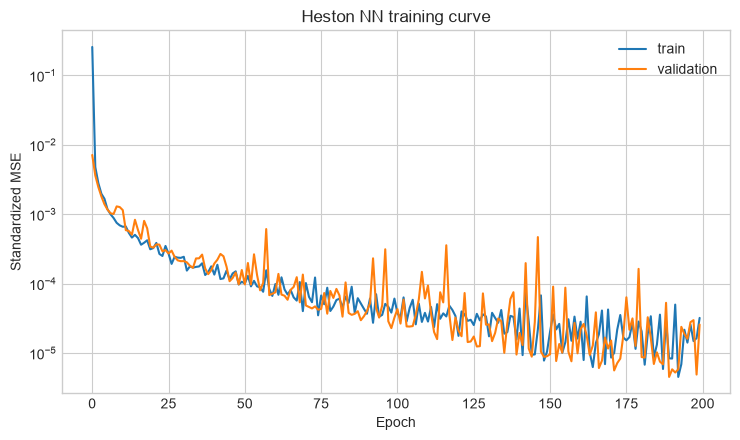

In [4]:
sx = StandardScaler().fit(X_train)
sy = StandardScaler().fit(y_train.reshape(-1, 1))

def tensor(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))

Xtr_t = tensor(sx.transform(X_train)).to(DEVICE)
Xva_t = tensor(sx.transform(X_val)).to(DEVICE)
Xte_t = tensor(sx.transform(X_test)).to(DEVICE)
ytr_t = tensor(sy.transform(y_train.reshape(-1, 1))).to(DEVICE)
yva_t = tensor(sy.transform(y_val.reshape(-1, 1))).to(DEVICE)

class HestonMLP(nn.Module):
    def __init__(self, n_features=len(FEATURE_NAMES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
fnn = HestonMLP().to(DEVICE)
optimizer = torch.optim.Adam(fnn.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
dataset = torch.utils.data.TensorDataset(Xtr_t, ytr_t)
loader = torch.utils.data.DataLoader(dataset, batch_size=1024, shuffle=True)
best_state, best_val, wait = None, float("inf"), 0
PATIENCE, MAX_EPOCHS = 18, 200
history = {"train_mse": [], "val_mse": []}
start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    fnn.train()
    train_sum = 0.0
    for xb, yb in loader:
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(fnn(xb), yb)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * len(xb)
    fnn.eval()
    with torch.no_grad():
        val_loss = sum(loss_fn(fnn(Xva_t[i:i+4096]), yva_t[i:i+4096]).item() * len(Xva_t[i:i+4096])
                       for i in range(0, len(Xva_t), 4096)) / len(Xva_t)
    train_loss = train_sum / len(Xtr_t)
    history["train_mse"].append(train_loss)
    history["val_mse"].append(val_loss)
    if val_loss < best_val:
        best_val, wait = val_loss, 0
        best_state = copy.deepcopy({k: v.detach().cpu() for k, v in fnn.state_dict().items()})
    else:
        wait += 1
    if epoch == 1 or epoch % 20 == 0:
        print(f"epoch {epoch:3d}: train={train_loss:.3e}, val={val_loss:.3e}")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

fnn.load_state_dict(best_state)
fnn = fnn.to(DEVICE).eval()
fnn_train_seconds = time.perf_counter() - start
print(f"NN fit time: {fnn_train_seconds:.1f}s; best standardized validation MSE={best_val:.3e}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(history["train_mse"], label="train")
ax.plot(history["val_mse"], label="validation")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Standardized MSE")
ax.set_title("Heston NN training curve")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Paper-style exact GPR

The reference paper models Heston European call prices calculated by FFT. Its Heston inputs are strike, maturity, rates/dividend yield, and the Heston parameters. It uses a quadratic basis for the mean, a squared-exponential covariance, and strictly positive observation noise; it reports training sizes of 5k, 10k, and 20k. Here the default 5k subset keeps exact GPR practical, while both models use the same dataset and held-out contexts. Increase `GPR_N` to 10,000 or 20,000 if memory and runtime allow.

The polynomial trend uses a quadratic expansion of the standardized inputs. GPR is fit to the residuals around that trend. Kernel hyperparameters are optimized on at most 1,500 rows, then fixed while the exact GP is refit on the configured subset.

In [5]:
from sklearn.base import clone

gpr_rng = np.random.default_rng(SEED + 1)
gpr_idx = gpr_rng.choice(len(train_df), size=min(GPR_N, len(train_df)), replace=False)
X_gpr_raw, y_gpr_raw = X_train[gpr_idx], y_train[gpr_idx]
gpr_sx = StandardScaler().fit(X_gpr_raw)
gpr_sy = StandardScaler().fit(y_gpr_raw.reshape(-1, 1))
X_gpr = gpr_sx.transform(X_gpr_raw)
y_gpr = gpr_sy.transform(y_gpr_raw.reshape(-1, 1)).ravel()
poly = PolynomialFeatures(degree=2, include_bias=True)
Phi = poly.fit_transform(X_gpr)
trend = Ridge(alpha=1e-6, fit_intercept=False).fit(Phi, y_gpr)
residual = y_gpr - trend.predict(Phi)

def make_kernel():
    return (ConstantKernel(1.0, (1e-2, 1e2))
            * RBF(length_scale=np.ones(X_gpr.shape[1]), length_scale_bounds=(1e-2, 1e2))
            + WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-8, 1e-1)))

fit_n = min(1_500, len(X_gpr))
tune_rng = np.random.default_rng(SEED + 2)
tune_idx = np.sort(tune_rng.choice(len(X_gpr), size=fit_n, replace=False))
tune_trend = Ridge(alpha=1e-6, fit_intercept=False).fit(Phi[tune_idx], y_gpr[tune_idx])
tune_residual = y_gpr[tune_idx] - tune_trend.predict(Phi[tune_idx])
tune_gp = GaussianProcessRegressor(kernel=make_kernel(), alpha=1e-10,
                                   normalize_y=False, n_restarts_optimizer=0,
                                   random_state=SEED)
gpr_start = time.perf_counter()
tune_gp.fit(X_gpr[tune_idx], tune_residual)
gpr_kernel = clone(tune_gp.kernel_)
gpr = GaussianProcessRegressor(kernel=gpr_kernel, alpha=1e-10,
                               optimizer=None, normalize_y=False)
gpr.fit(X_gpr, residual)
gpr_train_seconds = time.perf_counter() - gpr_start
print(f"Exact GPR rows={len(X_gpr):,}; fit time={gpr_train_seconds:.1f}s")
print("Fixed kernel:", gpr.kernel_)

def predict_gpr(X_raw, return_std=False):
    Xs = gpr_sx.transform(X_raw)
    trend_pred = trend.predict(poly.transform(Xs))
    if return_std:
        mean_resid, std_resid = gpr.predict(Xs, return_std=True)
        mean = gpr_sy.inverse_transform((trend_pred + mean_resid).reshape(-1, 1)).ravel()
        std = std_resid * float(gpr_sy.scale_[0])
        return mean, std
    residual_pred = gpr.predict(Xs)
    return gpr_sy.inverse_transform((trend_pred + residual_pred).reshape(-1, 1)).ravel()

Exact GPR rows=5,000; fit time=12.6s
Fixed kernel: 0.618**2 * RBF(length_scale=[0.402, 20.5, 23.6, 14.4, 16.9, 34.4, 24.1, 6.13, 11.9]) + WhiteKernel(noise_level=2.81e-07)


## 5. Held-out evaluation and saved artifacts

Report mean, maximum, and root-mean-square absolute error against the FFT label, plus R² and the fractions within 0.10 and 0.25 price units. The test contexts were not used for fitting either model. Save weights, scalers, exact GP state, the cached FFT dataset, and summary metrics for the final comparison notebook.

In [6]:
def predict_fnn(X_raw):
    Xt = tensor(sx.transform(X_raw)).to(DEVICE)
    with torch.no_grad():
        pred_scaled = fnn(Xt).cpu().numpy()
    return sy.inverse_transform(pred_scaled).ravel()

fnn_test_pred = predict_fnn(X_test)
gpr_test_pred, gpr_test_sd = predict_gpr(X_test, return_std=True)

def metric_row(name, pred):
    err = pred - y_test
    return {"model": name, "train_rows": len(X_train) if name == "FNN" else len(X_gpr),
            "MAE": mean_absolute_error(y_test, pred),
            "max_abs_error": np.abs(err).max(),
            "RMSE": mean_squared_error(y_test, pred) ** 0.5,
            "R2": r2_score(y_test, pred),
            "within_0.10": np.mean(np.abs(err) <= 0.10),
            "within_0.25": np.mean(np.abs(err) <= 0.25)}

metrics = pd.DataFrame([metric_row("FNN", fnn_test_pred), metric_row("GPR", gpr_test_pred)])
display(metrics.style.format({"MAE": "{:.5f}", "max_abs_error": "{:.5f}",
                              "RMSE": "{:.5f}", "R2": "{:.6f}",
                              "within_0.10": "{:.1%}", "within_0.25": "{:.1%}"}))

model_rows = [{"model": "FNN", "train_rows": len(X_train), "fit_seconds": fnn_train_seconds},
              {"model": "GPR", "train_rows": len(X_gpr), "fit_seconds": gpr_train_seconds}]
training_times = pd.DataFrame(model_rows)
metrics.to_csv(DATA_DIR / "heston_ml_test_metrics.csv", index=False)
training_times.to_csv(DATA_DIR / "heston_ml_training_times.csv", index=False)
pd.DataFrame(history).to_csv(DATA_DIR / "heston_fnn_training_curve.csv", index=False)

torch.save(fnn.state_dict(), MODEL_DIR / "heston_fnn.pt")
joblib.dump({"scaler_X": sx, "scaler_y": sy, "feature_names": FEATURE_NAMES,
             "train_seconds": fnn_train_seconds}, MODEL_DIR / "heston_fnn_preprocessing.joblib")
joblib.dump({"scaler_X": gpr_sx, "scaler_y": gpr_sy, "polynomial": poly,
             "trend": trend, "gp": gpr, "feature_names": FEATURE_NAMES,
             "train_seconds": gpr_train_seconds}, MODEL_DIR / "heston_gpr.joblib")
print("Saved Heston NN/GPR artifacts and metric tables.")

,model,train_rows,MAE,max_abs_error,RMSE,R2,within_0.10,within_0.25
0,FNN,70000,0.02961,0.22928,0.04059,0.999995,97.1%,100.0%
1,GPR,5000,0.00855,0.22965,0.01599,0.999999,99.7%,100.0%


Saved Heston NN/GPR artifacts and metric tables.
